Dataset Shape: (48842, 15)

First 5 Rows:
   age  workclass  fnlwgt     education  educational-num      marital-status  \
0   25    Private  226802          11th                7       Never-married   
1   38    Private   89814       HS-grad                9  Married-civ-spouse   
2   28  Local-gov  336951    Assoc-acdm               12  Married-civ-spouse   
3   44    Private  160323  Some-college               10  Married-civ-spouse   
4   18          ?  103497  Some-college               10       Never-married   

          occupation relationship   race  gender  capital-gain  capital-loss  \
0  Machine-op-inspct    Own-child  Black    Male             0             0   
1    Farming-fishing      Husband  White    Male             0             0   
2    Protective-serv      Husband  White    Male             0             0   
3  Machine-op-inspct      Husband  Black    Male          7688             0   
4                  ?    Own-child  White  Female             0             0 

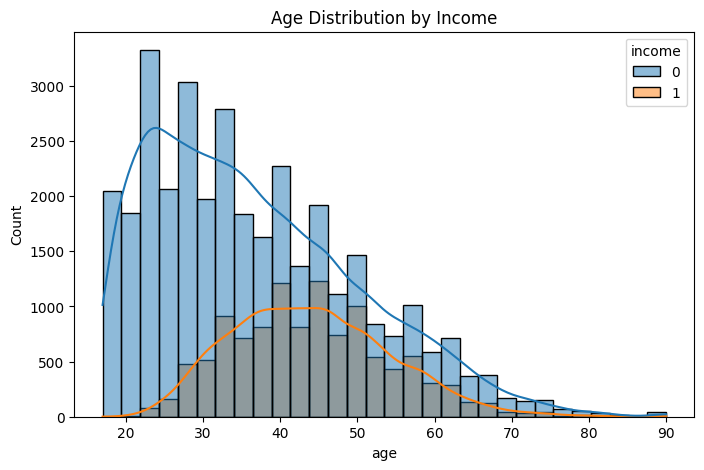

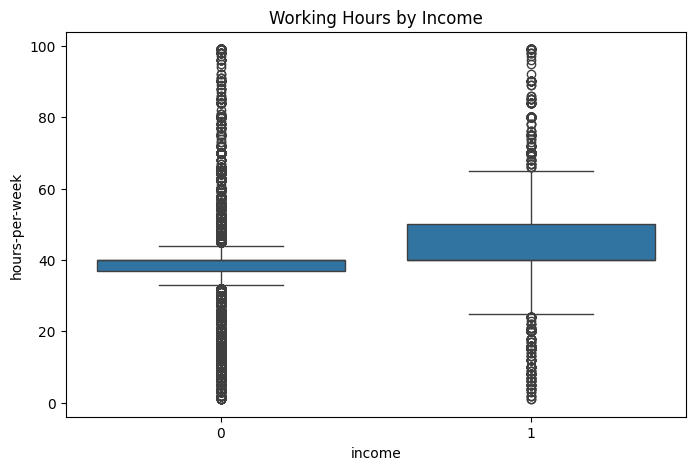

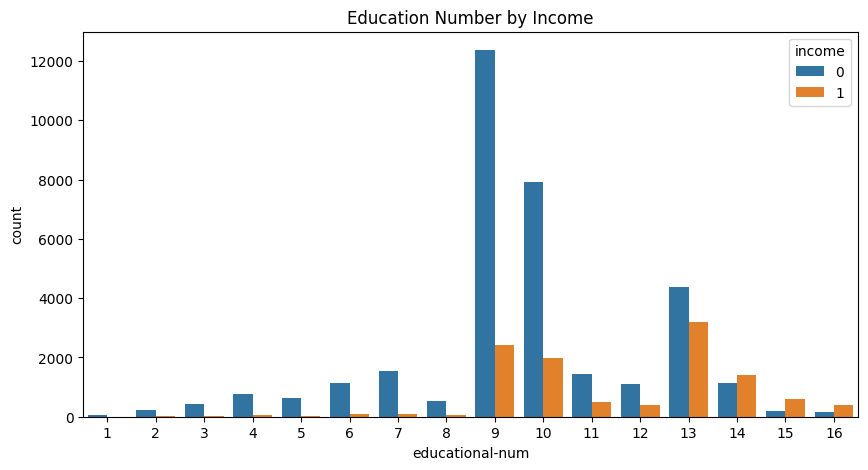

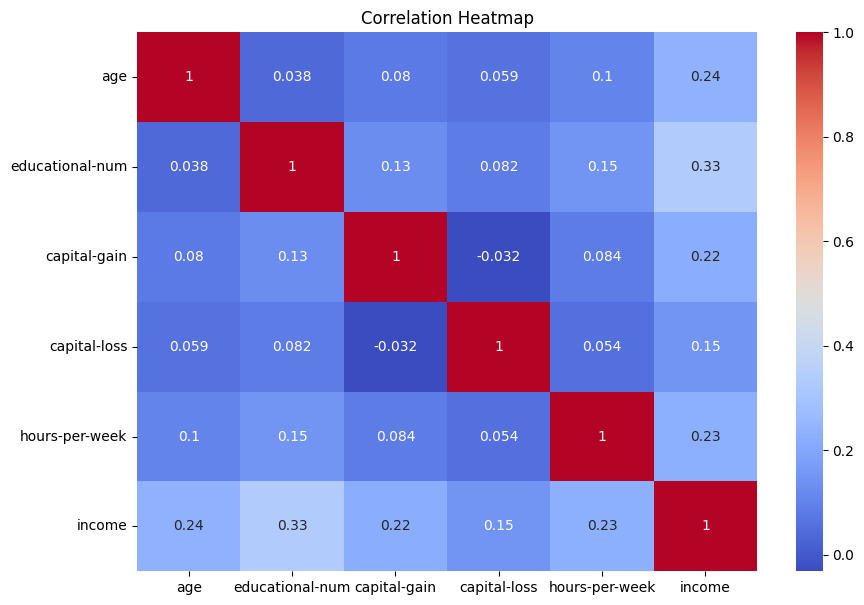


Total Features After Encoding: 80

Training Data Shape: (36177, 80)
Testing Data Shape: (9045, 80)

Training Class Ratio:
income
0    0.752163
1    0.247837
Name: proportion, dtype: float64

Testing Class Ratio:
income
0    0.752128
1    0.247872
Name: proportion, dtype: float64


In [1]:
# ==========================================
# TASK 1: DATA LOADING AND DATA CLEANING
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1.1: Load dataset

df = pd.read_csv("adult.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())

print("\nData Types:")
print(df.dtypes)

# Remove extra spaces from object columns

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Step 1.2: Handle missing values

df.replace("?", np.nan, inplace=True)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# Drop rows containing missing values

df.dropna(inplace=True)

print("\nShape After Removing Missing Values:")
print(df.shape)

# Step 1.3: Drop redundant columns

df.drop(columns=["fnlwgt", "education"], inplace=True)

print("\nShape After Dropping Columns:")
print(df.shape)

# Step 1.4: Encode target variable

# Remove trailing dot if present in income labels
df["income"] = df["income"].str.rstrip(".")

df["income"] = (df["income"] == ">50K").astype(int)

print("\nIncome Value Counts:")
print(df["income"].value_counts())

# Step 1.5: Exploratory Data Visualizations

# Histogram of age

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    hue="income",
    bins=30,
    kde=True
)

plt.title("Age Distribution by Income")
plt.show()


# Boxplot of working hours

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="income",
    y="hours-per-week"
)

plt.title("Working Hours by Income")
plt.show()


# Countplot of education number

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="educational-num",
    hue="income"
)

plt.title("Education Number by Income")
plt.show()


# Correlation heatmap

plt.figure(figsize=(10, 7))

corr = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()


# Step 1.6: Encode categorical columns and scale numerical columns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Separate input and target

X = df.drop("income", axis=1)
y = df["income"]

# One-hot encoding

X = pd.get_dummies(X, drop_first=True, dtype=int)

print("\nTotal Features After Encoding:", X.shape[1])

# Standard scaling

numeric_columns = [
    "age",
    "educational-num",
    "capital-gain",
    "capital-loss",
    "hours-per-week"
]

scaler = StandardScaler()

X[numeric_columns] = scaler.fit_transform(X[numeric_columns])

# Train test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Class Ratio:")
print(y_train.value_counts(normalize=True))

print("\nTesting Class Ratio:")
print(y_test.value_counts(normalize=True))

# Convert data into float32 for TensorFlow

X_train = X_train.astype("float32")
X_test = X_test.astype("float32")

y_train = y_train.astype("float32")
y_test = y_test.astype("float32")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,689 (73.00 KB)

 Trainable params: 18,689 (73.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8417 - loss: 0.3354 - val_accuracy: 0.8496 - val_loss: 0.3212
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8516 - loss: 0.3146 - val_accuracy: 0.8449 - val_loss: 0.3224
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8556 - loss: 0.3113 - val_accuracy: 0.8491 - val_loss: 0.3222
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8559 - loss: 0.3086 - val_accuracy: 0.8566 - val_loss: 0.3192
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8562 - loss: 0.3059 - val_accuracy: 0.8494 - val_loss: 0.3246
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8602 - loss: 0.3030 - val_accuracy: 0.8557 - val_loss: 0.3191
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8604 - loss: 0.3011 - val_accuracy: 0.8546 - val_loss: 0.3165
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8611 - loss: 0.2981 - val_accuracy: 0.

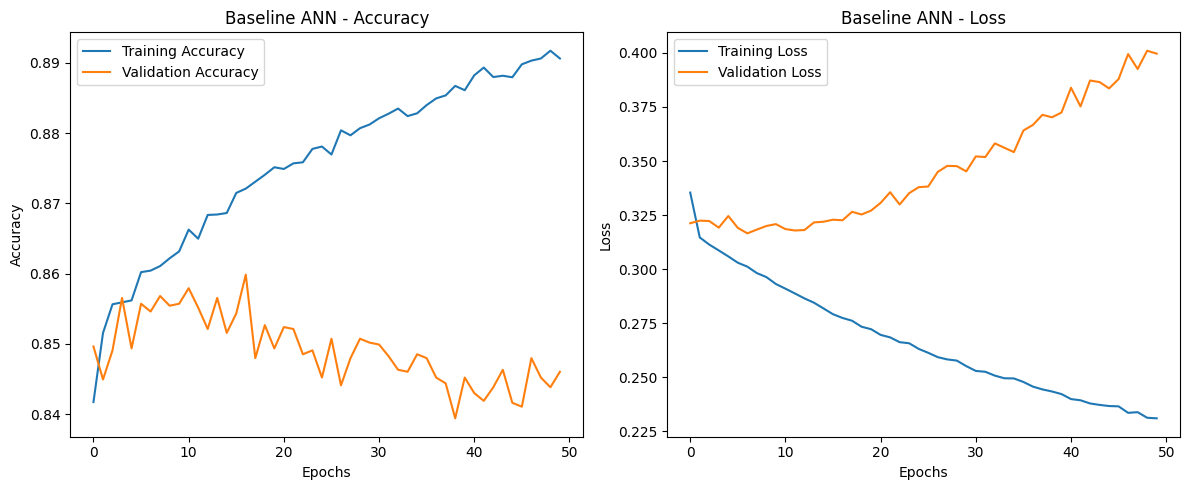

283/283 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

Baseline ANN Results
Accuracy: 0.8413488114980652
Precision: 0.692601431980907
Recall: 0.6471900089206066
F1 Score: 0.6691261240488817

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.89      0.91      0.90      6803
        >50K       0.69      0.65      0.67      2242

    accuracy                           0.84      9045
   macro avg       0.79      0.78      0.78      9045
weighted avg       0.84      0.84      0.84      9045



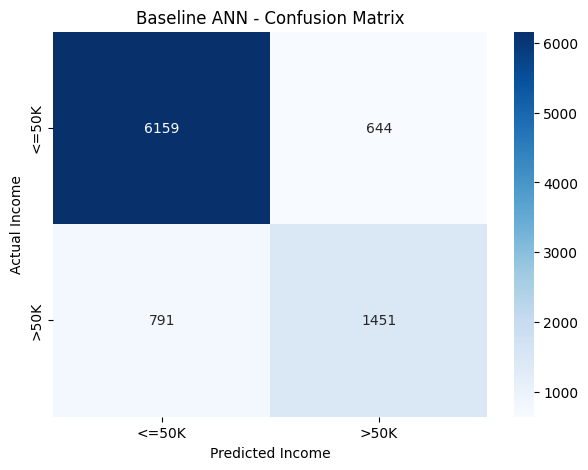


WHY TABULAR DATA SUITS ANN:

1. ANN can learn complex patterns.
2. Hidden layers learn relationships between features.
3. ANN can learn non-linear relationships.
4. It can combine numerical and encoded categorical features.
5. It can capture interactions such as age, education and occupation.



In [2]:
# ==========================================
# TASK 2: BASELINE ANN
# ==========================================

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


# Step 2.1: Create reusable ANN function

def build_ann(
    input_dim,
    hidden_units=[128, 64],
    activation="relu",
    initializer="glorot_uniform",
    optimizer="adam",
    loss="binary_crossentropy"
):

    model = keras.Sequential()

    model.add(
        keras.Input(shape=(input_dim,))
    )

    # First hidden layer

    model.add(
        layers.Dense(
            hidden_units[0],
            activation=activation,
            kernel_initializer=initializer,
            name="hidden_1"
        )
    )

    # Second hidden layer

    model.add(
        layers.Dense(
            hidden_units[1],
            activation=activation,
            kernel_initializer=initializer,
            name="hidden_2"
        )
    )

    # Output layer

    model.add(
        layers.Dense(
            1,
            activation="sigmoid",
            name="output"
        )
    )

    # Compile model

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=["accuracy"]
    )

    return model


# Step 2.2: Baseline ANN architecture

model_base = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation="relu",
    initializer="glorot_uniform"
)

# Display model summary

model_base.summary()


# Step 2.3: Train baseline ANN

history_base = model_base.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)


# Plot training and validation curves

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history_base.history["accuracy"], label="Training Accuracy")

plt.plot(history_base.history["val_accuracy"], label="Validation Accuracy")

plt.title("Baseline ANN - Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(history_base.history["loss"], label="Training Loss")

plt.plot(history_base.history["val_loss"], label="Validation Loss")

plt.title("Baseline ANN - Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


# Step 2.4: Evaluate baseline model

y_pred_prob = model_base.predict(X_test)

y_pred = (y_pred_prob > 0.5).astype(int).flatten()

# Calculate metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

f1 = f1_score(y_test, y_pred, zero_division=0)

print("\nBaseline ANN Results")

print("Accuracy:", accuracy)

print("Precision:", precision)

print("Recall:", recall)

print("F1 Score:", f1)


# Classification report

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["<=50K", ">50K"],
        zero_division=0
    )
)


# Confusion matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["<=50K", ">50K"],
    yticklabels=["<=50K", ">50K"]
)

plt.xlabel("Predicted Income")
plt.ylabel("Actual Income")

plt.title("Baseline ANN - Confusion Matrix")

plt.show()


# Step 2.5: Why ANN is suitable for tabular data

print("""
WHY TABULAR DATA SUITS ANN:

1. ANN can learn complex patterns.
2. Hidden layers learn relationships between features.
3. ANN can learn non-linear relationships.
4. It can combine numerical and encoded categorical features.
5. It can capture interactions such as age, education and occupation.
""")


Training Model: relu
Validation Accuracy: 0.8460475206375122
F1 Score: 0.6650135256988278

Training Model: tanh
Validation Accuracy: 0.8474295139312744
F1 Score: 0.657272269753397

Training Model: sigmoid
Validation Accuracy: 0.8562741875648499
F1 Score: 0.6808612440191387

Training Model: elu
Validation Accuracy: 0.858208954334259
F1 Score: 0.6816461684011353


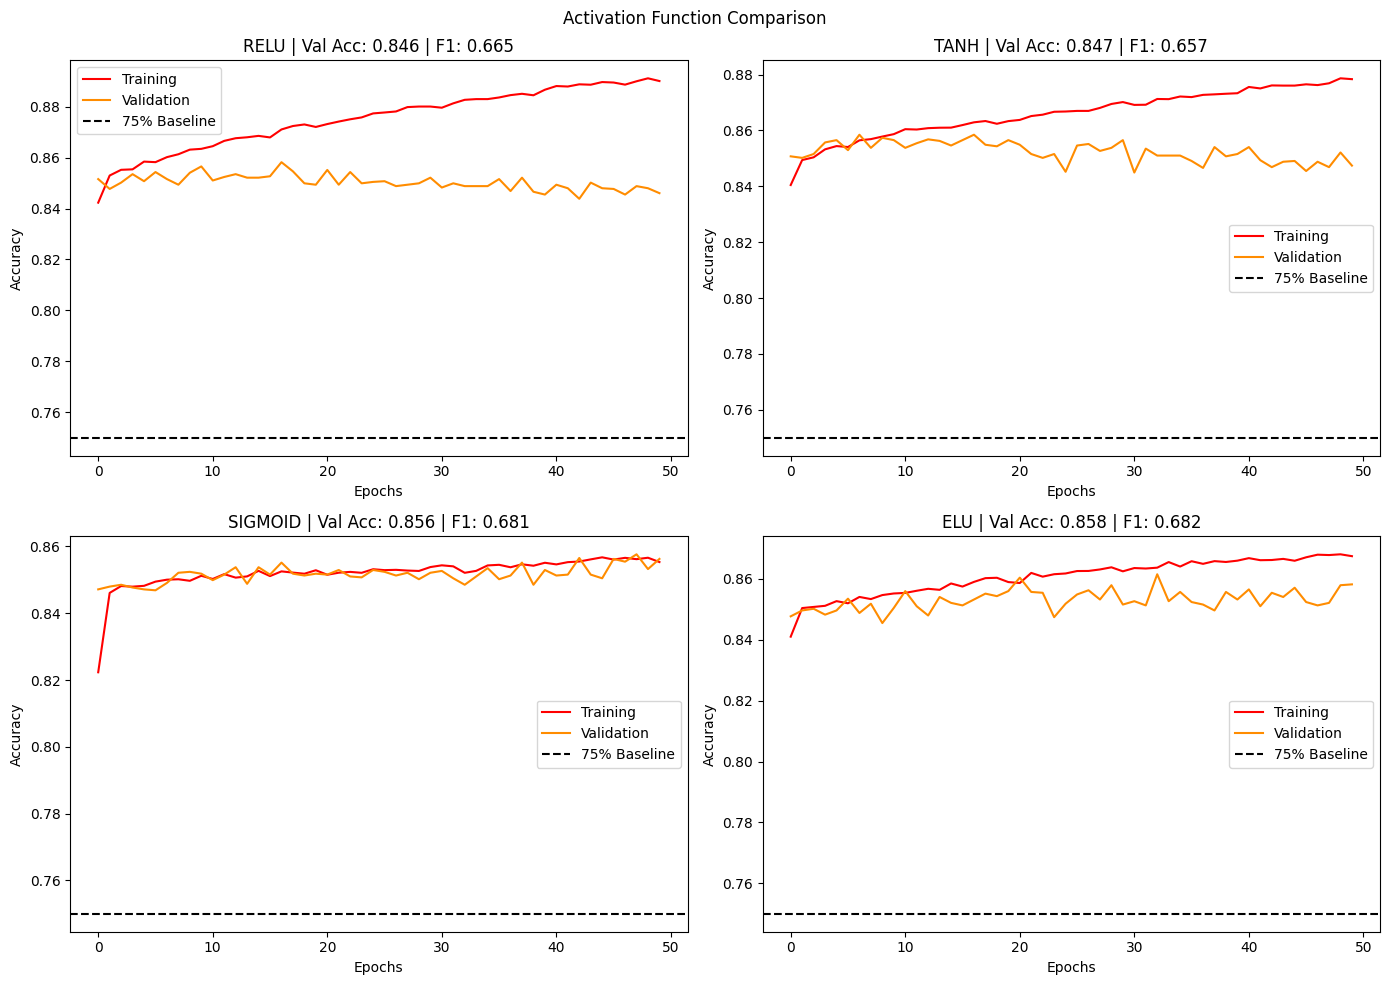

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
First hidden layer output:
[[0.         0.         0.33377308 0.5157909  0.0978079  0.03333879
  0.         0.         0.         0.         0.         0.
  0.24195912 0.         0.30285847 0.14756265 0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.39122683 0.01546979 0.5921459  0.         0.81775147
  0.         0.         0.09146634 0.58596796 0.         0.
  0.         0.         0.11606435 0.49823713 0.25845566 0.
  0.         0.         0.         0.25672725 0.2701671  0.3918327
  0.29899052 0.         0.         0.         0.         0.
  0.         0.         0.         0.01555488 0.         0.02398431
  0.07669052 0.         0.         0.         0.         0.
  0.         0.4274935  0.20403305 0.40599942 0.         0.
  0.         0.24475244 0.         0.9637766  0.         0.
  0.         0.         0.8698365  0.4528709  0.         0.
  0.         0.         0.21504094 0.88218117 0.0596103  0.
  0

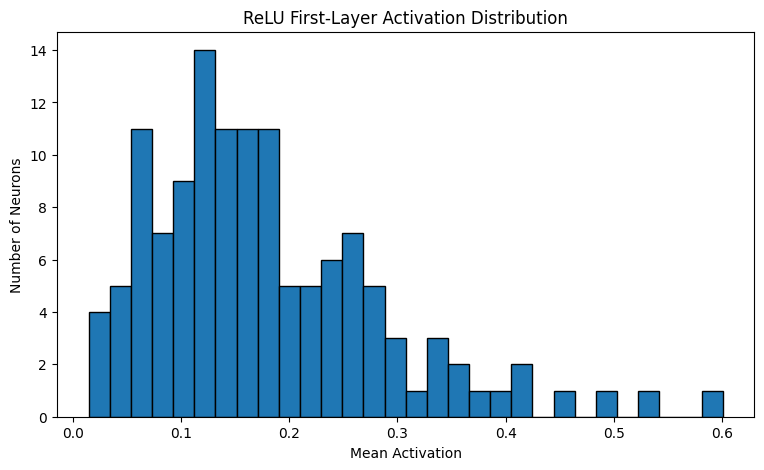

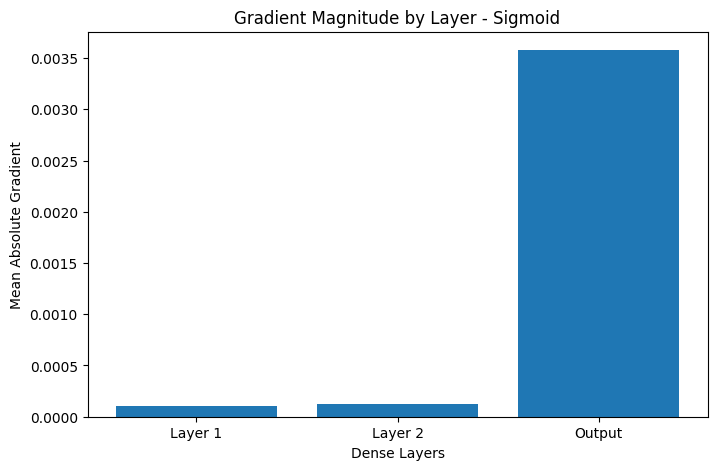


Activation Summary:
Activation                            Formula                     Output Range          Gradient Risk  Val Accuracy
      relu                          max(0, x)                    [0, infinity)           Dead Neurons      0.846048
      tanh                            tanh(x)                          (-1, 1)             Saturation      0.847430
   sigmoid                  1 / (1 + exp(-x))                           (0, 1)     Vanishing Gradient      0.856274
       elu x if x > 0 else alpha * (exp(x)-1) Approximately (-alpha, infinity) Lower Dead Neuron Risk      0.858209

Best Activation: elu

RECOMMENDATION:

ReLU is a good default choice for hidden layers.
ELU can help reduce the dead neuron problem.
Sigmoid is useful for binary classification output.
Tanh can be useful for some hidden-layer problems.



In [3]:
# ==========================================
# TASK 3: ACTIVATION FUNCTION COMPARISON
# ==========================================

from sklearn.metrics import f1_score

# Step 3.1: Train 4 models

activations = ["relu", "tanh", "sigmoid", "elu"]

histories = {}

activation_models = {}

activation_results = {}

for act in activations:

    print("\nTraining Model:", act)

    model = build_ann(
        input_dim=X_train.shape[1],
        hidden_units=[128, 64],
        activation=act,
        initializer="glorot_uniform"
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    histories[act] = history

    activation_models[act] = model

    # Evaluate model

    prediction = model.predict(
        X_test,
        verbose=0
    ).flatten()

    prediction = (prediction > 0.5).astype(int)

    f1 = f1_score(
        y_test,
        prediction,
        zero_division=0
    )

    val_accuracy = history.history["val_accuracy"][-1]

    activation_results[act] = {
        "val_accuracy": val_accuracy,
        "f1_score": f1
    }

    print("Validation Accuracy:", val_accuracy)

    print("F1 Score:", f1)


# Step 3.2: Activation comparison - 4 panel plot

plt.figure(figsize=(14, 10))

for i, act in enumerate(activations):

    plt.subplot(2, 2, i + 1)

    history = histories[act]

    plt.plot(
        history.history["accuracy"],
        label="Training",
        color="red"
    )

    plt.plot(
        history.history["val_accuracy"],
        label="Validation",
        color="darkorange"
    )

    # 75% baseline

    plt.axhline(
        y=0.75,
        linestyle="--",
        color="black",
        label="75% Baseline"
    )

    final_acc = activation_results[act]["val_accuracy"]

    final_f1 = activation_results[act]["f1_score"]

    plt.title(
        f"{act.upper()} | Val Acc: {final_acc:.3f} | F1: {final_f1:.3f}"
    )

    plt.xlabel("Epochs")

    plt.ylabel("Accuracy")

    plt.legend()

plt.suptitle("Activation Function Comparison")

plt.tight_layout()

plt.show()


# Step 3.3: Dead neuron check - ReLU

relu_model = activation_models["relu"]

# Get output of first hidden layer

# Step 1: Build the model
relu_model.build(input_shape=(None, X_train.shape[1]))

# Step 2: Call the model once
_ = relu_model(X_train[:1])

# Step 3: Get output of first hidden layer
intermediate_model = keras.Model(
    inputs=relu_model.inputs,
    outputs=relu_model.get_layer("hidden_1").output
)

# Step 4: Get intermediate output
hidden_output = intermediate_model.predict(X_train[:5])

print("First hidden layer output:")
print(hidden_output)

print("Output shape:", hidden_output.shape)
# Predict first 500 test samples

activations_relu = intermediate_model.predict(
    X_test[:500],
    verbose=0
)

# Calculate dead neuron fraction

dead_fraction = np.mean(activations_relu == 0)

print("\nDead Neuron Fraction:", dead_fraction)

# Mean activation per neuron

mean_activation = np.mean(
    activations_relu,
    axis=0
)

plt.figure(figsize=(9, 5))

plt.hist(
    mean_activation,
    bins=30,
    edgecolor="black"
)

plt.title("ReLU First-Layer Activation Distribution")

plt.xlabel("Mean Activation")

plt.ylabel("Number of Neurons")

plt.show()


# Step 3.4: Gradient flow check - Sigmoid hidden layers

sigmoid_model = activation_models["sigmoid"]

# Take one training batch

batch_x = tf.convert_to_tensor(
    X_train[:256].values,
    dtype=tf.float32
)

batch_y = tf.convert_to_tensor(
    y_train[:256].values.reshape(-1, 1),
    dtype=tf.float32
)

# Calculate gradients

with tf.GradientTape(persistent=True) as tape:

    predictions = sigmoid_model(
        batch_x,
        training=True
    )

    loss_value = keras.losses.binary_crossentropy(
        batch_y,
        predictions
    )

    loss_value = tf.reduce_mean(loss_value)


# Get Dense layers

dense_layers = [
    layer for layer in sigmoid_model.layers
    if isinstance(layer, layers.Dense)
]

gradient_values = []

for layer in dense_layers:

    gradient = tape.gradient(
        loss_value,
        layer.kernel
    )

    mean_gradient = tf.reduce_mean(
        tf.abs(gradient)
    ).numpy()

    gradient_values.append(mean_gradient)

del tape


# Plot gradient magnitudes

plt.figure(figsize=(8, 5))

plt.bar(
    ["Layer 1", "Layer 2", "Output"],
    gradient_values
)

plt.title("Gradient Magnitude by Layer - Sigmoid")

plt.xlabel("Dense Layers")

plt.ylabel("Mean Absolute Gradient")

plt.show()


# Step 3.5: Activation summary table

activation_summary = pd.DataFrame({
    "Activation": activations,
    "Formula": [
        "max(0, x)",
        "tanh(x)",
        "1 / (1 + exp(-x))",
        "x if x > 0 else alpha * (exp(x)-1)"
    ],
    "Output Range": [
        "[0, infinity)",
        "(-1, 1)",
        "(0, 1)",
        "Approximately (-alpha, infinity)"
    ],
    "Gradient Risk": [
        "Dead Neurons",
        "Saturation",
        "Vanishing Gradient",
        "Lower Dead Neuron Risk"
    ],
    "Val Accuracy": [
        activation_results[a]["val_accuracy"]
        for a in activations
    ]
})

print("\nActivation Summary:")

print(activation_summary.to_string(index=False))


# Best activation

best_activation = max(
    activation_results,
    key=lambda a: activation_results[a]["val_accuracy"]
)

print("\nBest Activation:", best_activation)

print("""
RECOMMENDATION:

ReLU is a good default choice for hidden layers.
ELU can help reduce the dead neuron problem.
Sigmoid is useful for binary classification output.
Tanh can be useful for some hidden-layer problems.
""")


Training Initializer: glorot_uniform
Validation Accuracy: 0.8449419736862183
F1 Score: 0.6584146631754344

Training Initializer: glorot_normal
Validation Accuracy: 0.8432835936546326
F1 Score: 0.6610858646256876

Training Initializer: he_uniform
Validation Accuracy: 0.8402432203292847
F1 Score: 0.6525505293551492

Training Initializer: he_normal
Validation Accuracy: 0.8399668335914612
F1 Score: 0.6566533677540484

Training Initializer: zeros
Validation Accuracy: 0.7526257634162903
F1 Score: 0.0

WHY WEIGHT INITIALIZATION MATTERS:

1. All-zero initialization:
   Every neuron receives the same gradient.
   Neurons learn identical features.
   This causes the symmetry problem.

2. Glorot initialization:
   Suitable for sigmoid and tanh activations.
   Helps maintain stable signal variance.

3. He initialization:
   Suitable for ReLU activation.
   Helps maintain activation variance
   when some neurons output zero.

4. Good initialization:
   Helps neural networks train faster
   and imp

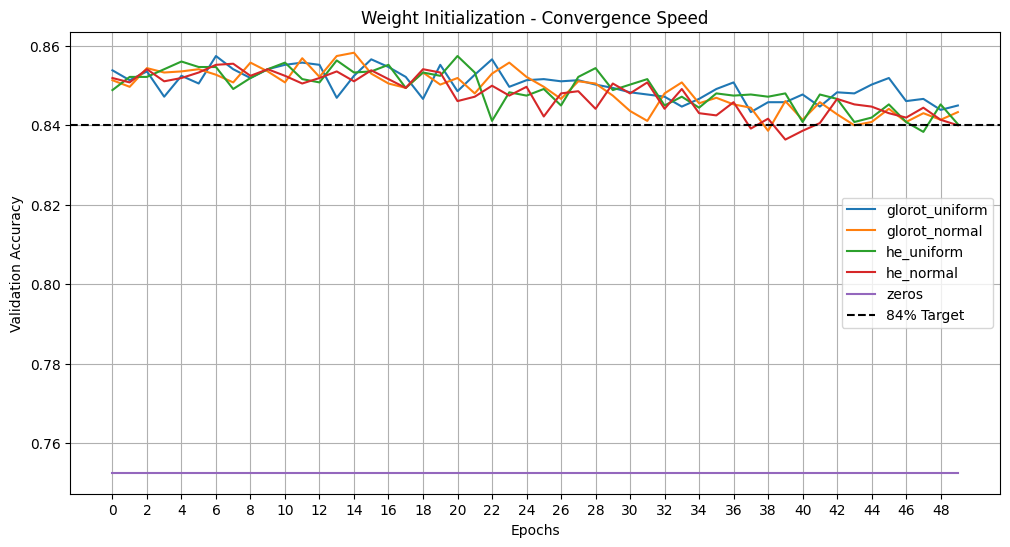


First Epoch Reaching 82% Validation Accuracy:
glorot_uniform : 1
glorot_normal : 1
he_uniform : 1
he_normal : 1
zeros : Did not reach 82%


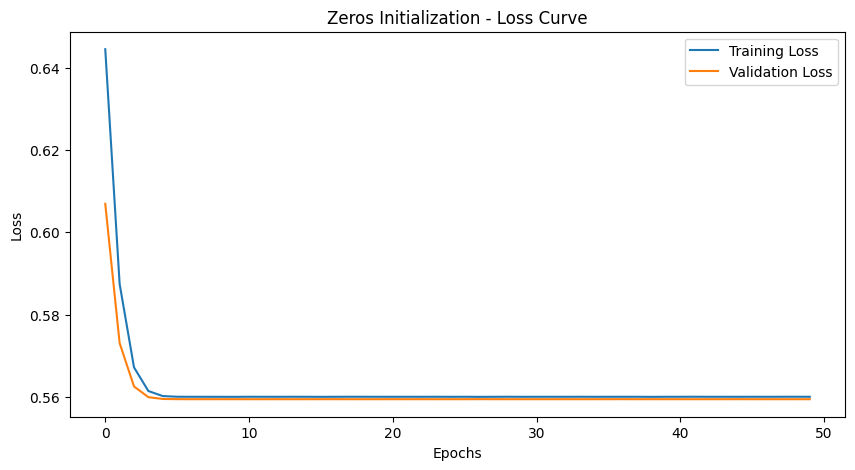

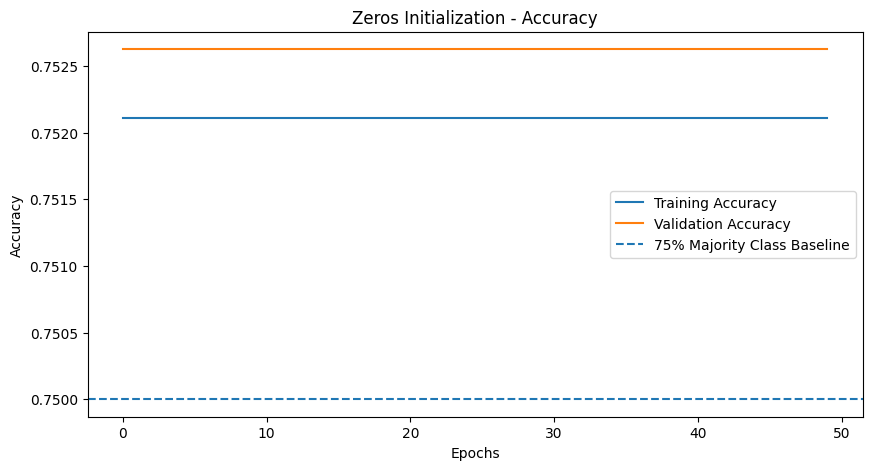


ZERO INITIALIZATION EXPLANATION:

When all hidden-layer weights are initialized to zero,
all neurons receive identical inputs and gradients.

Therefore, neurons learn identical features.

This is called the symmetry problem.

Zero initialization is not suitable for
hidden layers of neural networks.



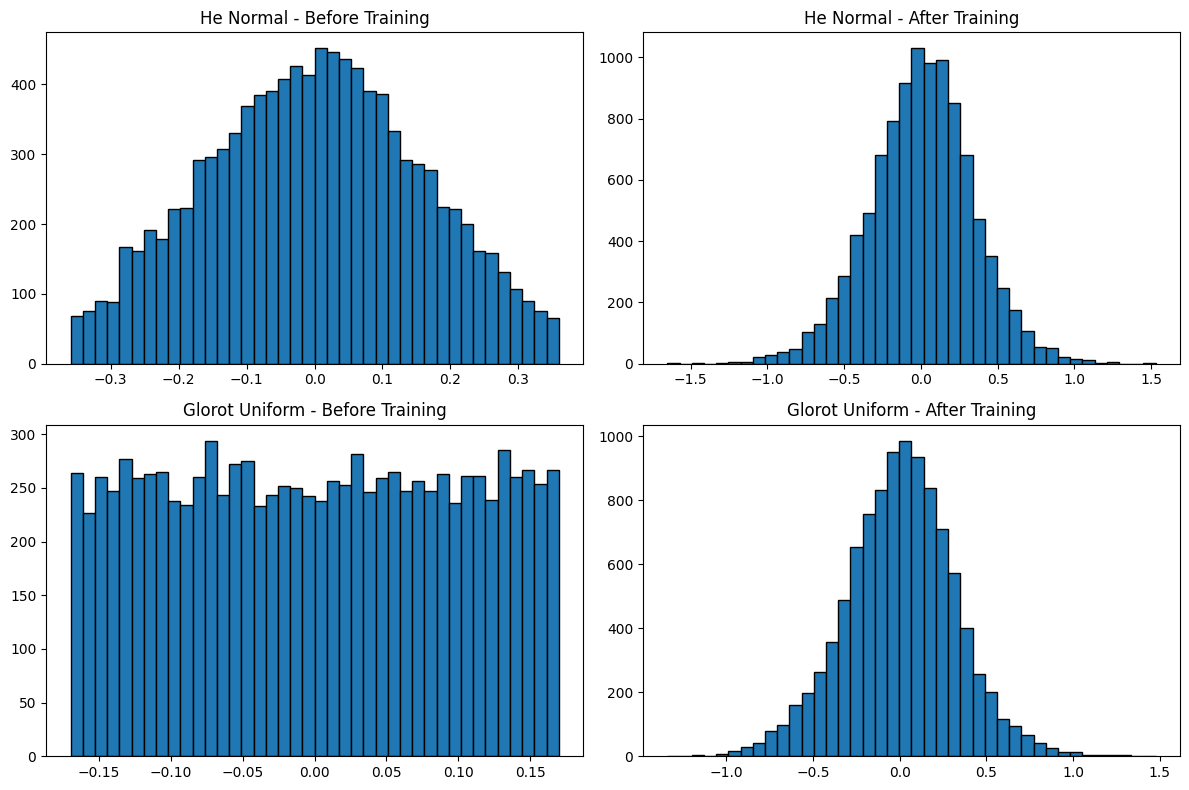


Final Weight Initialization Comparison:
   Initializer  Validation Accuracy  F1 Score
glorot_uniform             0.844942  0.658415
 glorot_normal             0.843284  0.661086
    he_uniform             0.840243  0.652551
     he_normal             0.839967  0.656653
         zeros             0.752626  0.000000

Best Weight Initializer: glorot_uniform

TASK 1 TO TASK 4 COMPLETED!


In [11]:
# ==========================================
# TASK 4: WEIGHT INITIALIZATION
# ==========================================

# Step 4.1: Train 5 models with different initializers

initializers = [
    "glorot_uniform",
    "glorot_normal",
    "he_uniform",
    "he_normal",
    "zeros"
]

initializer_histories = {}

initializer_models = {}

initializer_results = {}

initial_weights = {}

trained_weights = {}


for init in initializers:

    print("\nTraining Initializer:", init)

    model = build_ann(
        input_dim=X_train.shape[1],
        hidden_units=[128, 64],
        activation="relu",
        initializer=init
    )

    # Store initial weights before training

    initial_weights[init] = (
        model.get_layer("hidden_1").get_weights()[0].copy()
    )

    # Train model

    history = model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    # Store history and model

    initializer_histories[init] = history

    initializer_models[init] = model

    # Store weights after training

    trained_weights[init] = (
        model.get_layer("hidden_1").get_weights()[0].copy()
    )

    # Evaluate model

    prediction = model.predict(
        X_test,
        verbose=0
    ).flatten()

    prediction = (prediction > 0.5).astype(int)

    f1 = f1_score(
        y_test,
        prediction,
        zero_division=0
    )

    val_acc = history.history["val_accuracy"][-1]

    initializer_results[init] = {
        "val_accuracy": val_acc,
        "f1_score": f1
    }

    print("Validation Accuracy:", val_acc)

    print("F1 Score:", f1)


# Step 4.2: Why initialization matters

print("""
WHY WEIGHT INITIALIZATION MATTERS:

1. All-zero initialization:
   Every neuron receives the same gradient.
   Neurons learn identical features.
   This causes the symmetry problem.

2. Glorot initialization:
   Suitable for sigmoid and tanh activations.
   Helps maintain stable signal variance.

3. He initialization:
   Suitable for ReLU activation.
   Helps maintain activation variance
   when some neurons output zero.

4. Good initialization:
   Helps neural networks train faster
   and improves gradient flow.
""")


# Step 4.3: Convergence speed comparison

plt.figure(figsize=(12, 6))

for init in initializers:

    history = initializer_histories[init]

    plt.plot(
        history.history["val_accuracy"],
        label=init
    )

# 84% target benchmark

plt.axhline(
    y=0.84,
    linestyle="--",
    color="black",
    label="84% Target"
)

plt.title("Weight Initialization - Convergence Speed")

plt.xlabel("Epochs")

plt.ylabel("Validation Accuracy")

plt.xticks(range(0, 50, 2))

plt.legend()

plt.grid()

plt.show()


# Find first epoch reaching 82% validation accuracy

print("\nFirst Epoch Reaching 82% Validation Accuracy:")

for init in initializers:

    values = initializer_histories[init].history["val_accuracy"]

    epochs_reached = [
        i + 1 for i, value in enumerate(values)
        if value >= 0.82
    ]

    if epochs_reached:

        print(init, ":", epochs_reached[0])

    else:

        print(init, ": Did not reach 82%")


# Step 4.4: Zeros failure demonstration

zero_model = initializer_models["zeros"]

zero_history = initializer_histories["zeros"]

# Plot training loss

plt.figure(figsize=(10, 5))

plt.plot(
    zero_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    zero_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Zeros Initialization - Loss Curve")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.show()


# Plot training and validation accuracy

plt.figure(figsize=(10, 5))

plt.plot(
    zero_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    zero_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.axhline(
    y=0.75,
    linestyle="--",
    label="75% Majority Class Baseline"
)

plt.title("Zeros Initialization - Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()

plt.show()


print("""
ZERO INITIALIZATION EXPLANATION:

When all hidden-layer weights are initialized to zero,
all neurons receive identical inputs and gradients.

Therefore, neurons learn identical features.

This is called the symmetry problem.

Zero initialization is not suitable for
hidden layers of neural networks.
""")


# Step 4.5: Weight distribution visualization

plt.figure(figsize=(12, 8))


# He Normal - Before Training

plt.subplot(2, 2, 1)

plt.hist(
    initial_weights["he_normal"].flatten(),
    bins=40,
    edgecolor="black"
)

plt.title("He Normal - Before Training")


# He Normal - After Training

plt.subplot(2, 2, 2)

plt.hist(
    trained_weights["he_normal"].flatten(),
    bins=40,
    edgecolor="black"
)

plt.title("He Normal - After Training")


# Glorot Uniform - Before Training

plt.subplot(2, 2, 3)

plt.hist(
    initial_weights["glorot_uniform"].flatten(),
    bins=40,
    edgecolor="black"
)

plt.title("Glorot Uniform - Before Training")


# Glorot Uniform - After Training

plt.subplot(2, 2, 4)

plt.hist(
    trained_weights["glorot_uniform"].flatten(),
    bins=40,
    edgecolor="black"
)

plt.title("Glorot Uniform - After Training")


plt.tight_layout()

plt.show()


# Final initializer comparison

initializer_summary = pd.DataFrame([
    {
        "Initializer": init,
        "Validation Accuracy": initializer_results[init]["val_accuracy"],
        "F1 Score": initializer_results[init]["f1_score"]
    }
    for init in initializers
])

print("\nFinal Weight Initialization Comparison:")

print(initializer_summary.to_string(index=False))


best_initializer = max(
    initializer_results,
    key=lambda x: initializer_results[x]["val_accuracy"]
)

print("\nBest Weight Initializer:", best_initializer)

print("\nTASK 1 TO TASK 4 COMPLETED!")

Baseline Loss: binary_crossentropy
Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8435 - loss: 0.1077 - val_accuracy: 0.8510 - val_loss: 0.1031
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8535 - loss: 0.1006 - val_accuracy: 0.8546 - val_loss: 0.1017
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8556 - loss: 0.0992 - val_accuracy: 0.8499 - val_loss: 0.1043
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8586 - loss: 0.0979 - val_accuracy: 0.8538 - val_loss: 0.1011
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8593 - loss: 0.0967 - val_accuracy: 0.8524 - val_loss: 0.1021
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8623 - loss: 0.0959 - val_accuracy: 0.8566 - val_loss: 0.1001
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8630 - loss: 0.0951 - val_accuracy: 0.8571 - val_loss: 0.1011
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.864

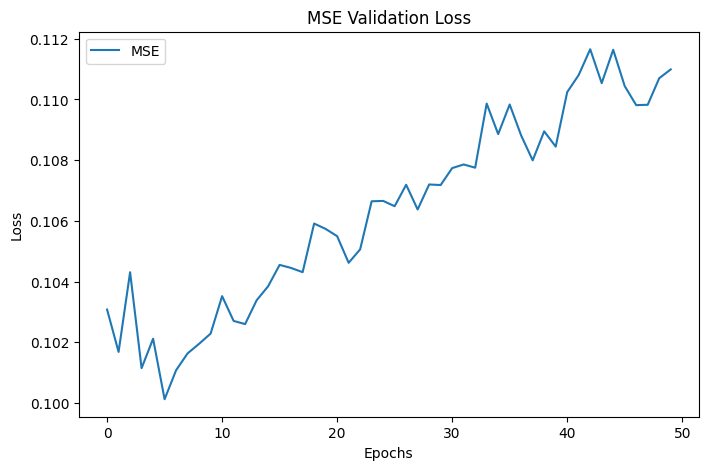

Class Weights: {0: np.float64(0.6647495498144133), 1: np.float64(2.0174548293553425)}
Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7996 - loss: 0.3961 - val_accuracy: 0.8129 - val_loss: 0.3800
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8099 - loss: 0.3718 - val_accuracy: 0.8049 - val_loss: 0.3790
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8114 - loss: 0.3659 - val_accuracy: 0.8035 - val_loss: 0.3837
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8136 - loss: 0.3620 - val_accuracy: 0.7844 - val_loss: 0.4194
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8150 - loss: 0.3585 - val_accuracy: 0.7913 - val_loss: 0.4087
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8168 - loss: 0.3558 - val_accuracy: 0.7957 - val_loss: 0.3949
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8164 - loss: 0.3523 - val_accuracy: 0.7960 - val_loss: 0.3957
Epoch 8/50
509/509

In [12]:
# ==========================================
# TASK 5: LOSS FUNCTIONS
# ==========================================

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ------------------------------------------
# 5.1 Binary Cross Entropy
# ------------------------------------------

print("Baseline Loss:", model_base.loss)

# Baseline BCE predictions
y_pred_bce = (model_base.predict(X_test, verbose=0).flatten() > 0.5).astype(int)

bce_f1 = f1_score(y_test, y_pred_bce, zero_division=0)


# ------------------------------------------
# 5.2 Mean Squared Error (MSE)
# ------------------------------------------

model_mse = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation="relu",
    initializer="he_normal",
    loss="mean_squared_error"
)

history_mse = model_mse.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

y_pred_mse = (
    model_mse.predict(X_test, verbose=0).flatten() > 0.5
).astype(int)

mse_f1 = f1_score(y_test, y_pred_mse, zero_division=0)

plt.figure(figsize=(8, 5))
plt.plot(history_mse.history["val_loss"], label="MSE")
plt.title("MSE Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()


# ------------------------------------------
# 5.3 Weighted Binary Cross Entropy
# ------------------------------------------

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weight_dict = {
    0: weights[0],
    1: weights[1]
}

print("Class Weights:", class_weight_dict)

model_wbce = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation="relu",
    initializer="he_normal",
    loss="binary_crossentropy"
)

history_wbce = model_wbce.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    class_weight=class_weight_dict,
    verbose=1
)

y_pred_wbce = (
    model_wbce.predict(X_test, verbose=0).flatten() > 0.5
).astype(int)

wbce_precision = precision_score(y_test, y_pred_wbce, zero_division=0)
wbce_recall = recall_score(y_test, y_pred_wbce, zero_division=0)
wbce_f1 = f1_score(y_test, y_pred_wbce, zero_division=0)


# ------------------------------------------
# 5.4 Focal Loss
# ------------------------------------------

def focal_loss(gamma=2.0, alpha=0.25):

    def loss_function(y_true, y_pred):

        y_true = tf.cast(
            tf.reshape(y_true, tf.shape(y_pred)),
            tf.float32
        )

        y_pred = tf.clip_by_value(
            y_pred, 1e-7, 1 - 1e-7
        )

        p_t = (
            y_true * y_pred
            + (1 - y_true) * (1 - y_pred)
        )

        alpha_t = (
            y_true * alpha
            + (1 - y_true) * (1 - alpha)
        )

        bce = keras.backend.binary_crossentropy(
            y_true, y_pred
        )

        focal = (
            alpha_t
            * tf.pow(1 - p_t, gamma)
            * bce
        )

        return tf.reduce_mean(focal)

    return loss_function


model_focal = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation="relu",
    initializer="he_normal",
    loss=focal_loss(gamma=2.0, alpha=0.25)
)

history_focal = model_focal.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

y_pred_focal = (
    model_focal.predict(X_test, verbose=0).flatten() > 0.5
).astype(int)

focal_precision = precision_score(y_test, y_pred_focal, zero_division=0)
focal_recall = recall_score(y_test, y_pred_focal, zero_division=0)
focal_f1 = f1_score(y_test, y_pred_focal, zero_division=0)


# ------------------------------------------
# 5.5 Loss Function Summary Table
# ------------------------------------------

loss_summary = pd.DataFrame({

    "Loss Function": [
        "Binary Cross Entropy",
        "Mean Squared Error",
        "Weighted BCE",
        "Focal Loss"
    ],

    "Formula": [
        "-[y log(p)+(1-y)log(1-p)]",
        "(y-p)^2",
        "Class Weighted BCE",
        "-alpha*(1-pt)^gamma*log(pt)"
    ],

    "Best For": [
        "Binary Classification",
        "Regression",
        "Class Imbalance",
        "Hard Examples"
    ],

    "F1 Score": [
        bce_f1,
        mse_f1,
        wbce_f1,
        focal_f1
    ]
})

print("\nLOSS FUNCTION SUMMARY")
print(loss_summary.to_string(index=False))


# Find best loss function

f1_results = {
    "Binary Cross Entropy": bce_f1,
    "MSE": mse_f1,
    "Weighted BCE": wbce_f1,
    "Focal Loss": focal_f1
}

best_loss = max(f1_results, key=f1_results.get)

print("\nBest Loss Function:", best_loss)

print("\nTASK 5 COMPLETED!")

Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,457 (76.00 KB)

 Trainable params: 19,073 (74.50 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8351 - loss: 0.3508 - val_accuracy: 0.8483 - val_loss: 0.3314
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8512 - loss: 0.3207 - val_accuracy: 0.8532 - val_loss: 0.3244
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8529 - loss: 0.3149 - val_accuracy: 0.8538 - val_loss: 0.3248
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8538 - loss: 0.3118 - val_accuracy: 0.8516 - val_loss: 0.3218
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8540 - loss: 0.3088 - val_accuracy: 0.8516 - val_loss: 0.3228
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8565 - loss: 0.3064 - val_accuracy: 0.8560 - val_loss: 0.3200
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8576 - loss: 0.3038 - val_accuracy: 0.8541 - val_loss: 0.3231
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8593 - loss: 0.3026 - val_accuracy: 0.

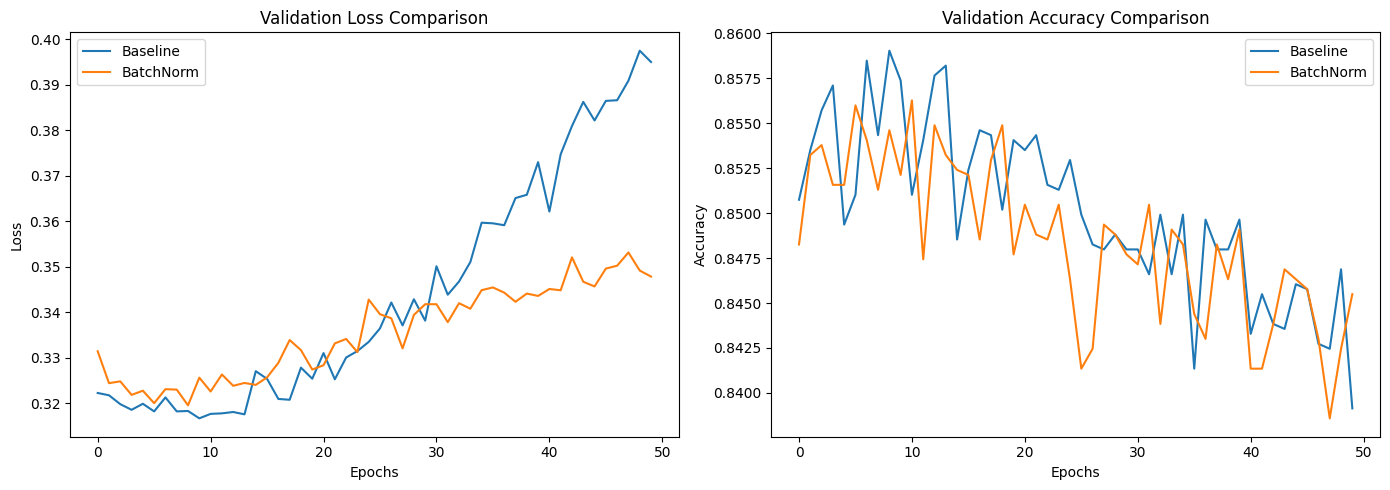


BASELINE ANN
Accuracy: 0.835820895522388
F1 Score: 0.631055900621118

BATCH NORMALIZATION ANN
Accuracy: 0.840906578220011
F1 Score: 0.6563171721996657
Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8312 - loss: 0.3718 - val_accuracy: 0.8463 - val_loss: 0.3329
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8514 - loss: 0.3219 - val_accuracy: 0.8477 - val_loss: 0.3276
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8517 - loss: 0.3168 - val_accuracy: 0.8405 - val_loss: 0.3298
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8565 - loss: 0.3105 - val_accuracy: 0.8452 - val_loss: 0.3266
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8559 - loss: 0.3079 - val_accuracy: 0.8543 - val_loss: 0.3215
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8570 - loss: 0.3059 - val_accuracy: 0.8505 - val_loss: 0.3228
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8577 - loss: 0

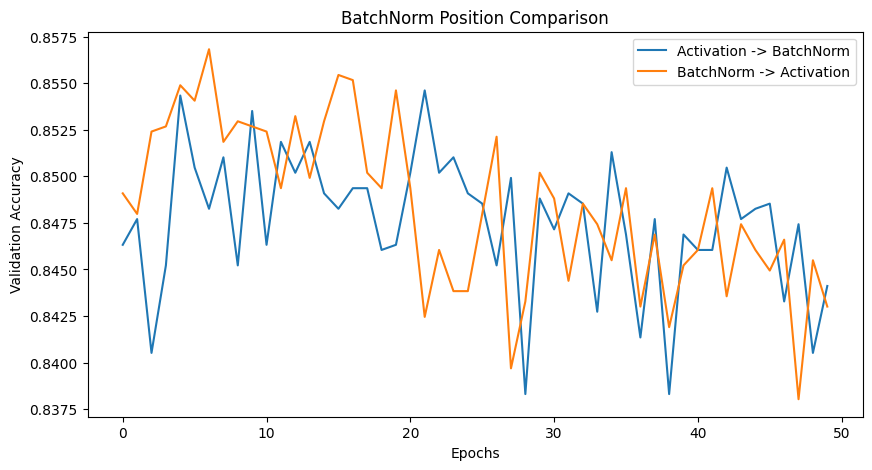


Activation -> BatchNorm: 0.844112753868103
BatchNorm -> Activation: 0.8430072069168091

Gamma Values:
[0.9249517  1.0696249  1.0461024  0.90697753 1.2392472  1.0003585
 1.1360935  1.0956051  0.9270345  0.8956264  0.74811095 1.1778207
 1.0082688  0.99785024 1.2282612  0.83744586 0.9599243  1.0294906
 0.9331343  0.77652484 1.1931694  1.0926291  0.9052568  0.94426364
 0.98998594 1.0326236  1.0239047  1.2993038  0.9707048  0.9566197
 0.8529621  0.99225456 1.0410063  1.1061764  1.0189356  1.026201
 1.148649   1.0050216  0.87639666 1.0716428  0.9389379  0.9649784
 0.97818315 0.81411314 0.9850121  1.0261205  0.925902   1.0069613
 1.027425   0.8799258  0.9371117  0.99315506 1.0359985  0.96074677
 0.95593107 1.1517662  0.9478857  1.033891   0.99816114 1.1485852
 0.8026552  1.1175402  0.87583226 0.99979514 1.1187783  1.171056
 0.94234556 1.1090964  1.0144923  1.0861969  0.98858756 1.0358883
 1.1115868  1.0664378  1.0391191  0.9883616  0.9308295  0.9973349
 0.86595815 0.9898315  0.9735402  0.959

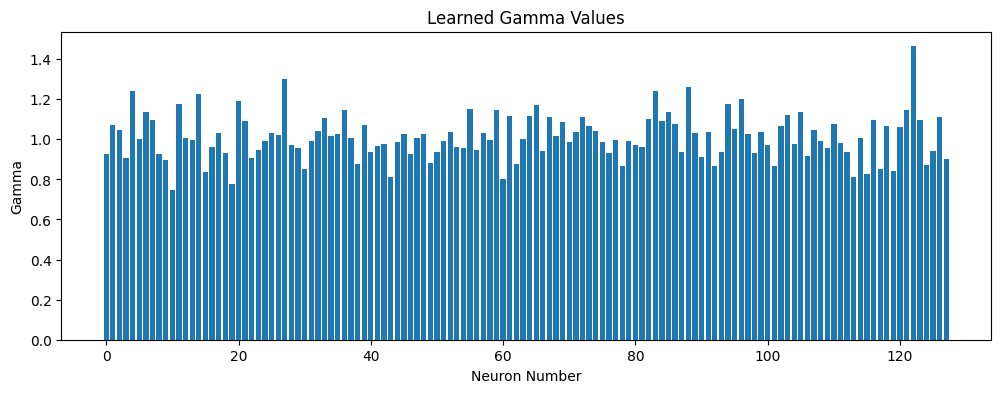

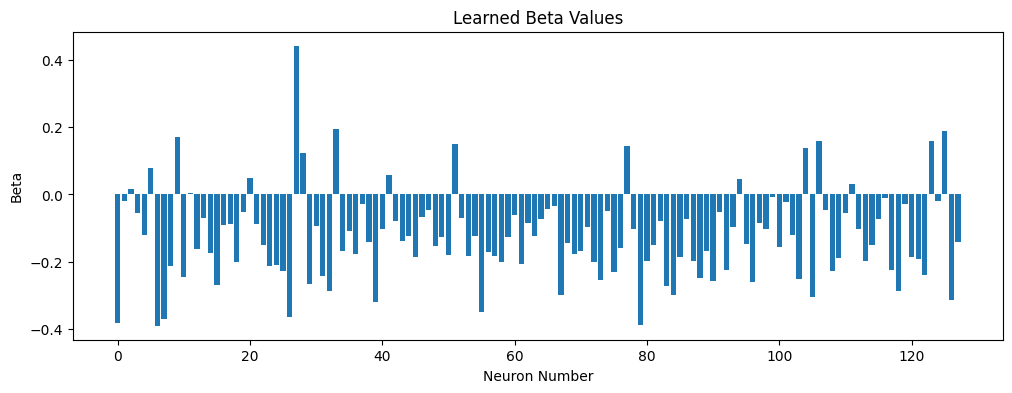


Gamma Shape: (128,)
Beta Shape: (128,)
Moving Mean: [-0.84739685  0.37603208  0.15333113 -0.3890483  -0.39738017  0.16160026
 -0.45934895 -0.5825959  -0.04257753 -0.20332807 -0.04758804  0.62762934
  0.18218444 -0.03042124 -0.09916041  0.02051644 -0.5739324  -0.043024
 -0.40233618  0.22508715 -0.05552608  0.16649653 -0.23270492 -0.03806133
 -0.2945719   0.28816727 -0.4726786   1.0839709   0.57004476 -0.4965796
  0.33953878 -0.13037296  0.10467953 -0.1480693  -0.25943705 -0.2993572
 -0.16809087  0.28857464  0.03795202 -0.16069995  0.08037753 -0.1515027
 -0.15782027 -0.5579309  -0.37949637  0.68828905  0.33273312 -0.42776856
 -0.09671102 -0.26693162 -0.44723827  0.69323474 -0.6643681   0.3108995
  0.15975073  0.14348054 -0.57968426  0.16913815 -0.32805634  0.10980303
 -0.29196602 -0.18295382 -0.20313026  0.79496217 -0.09269328 -0.09657653
 -0.2720263   0.02220655  0.24749613 -0.15858684  0.4899983  -0.53983855
  0.23687127  0.27322385  0.3120777   0.5933654   0.17497122  0.5845089
  0.1

In [13]:
# ==========================================
# TASK 6: BATCH NORMALIZATION
# ==========================================

# ------------------------------------------
# 6.1 Build ANN with Batch Normalization
# ------------------------------------------

model_bn = keras.Sequential([

    keras.Input(shape=(X_train.shape[1],)),

    layers.Dense(128, kernel_initializer="he_normal"),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Dense(64, kernel_initializer="he_normal"),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Dense(1, activation="sigmoid")
])

model_bn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_bn.summary()

history_bn = model_bn.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)


# ------------------------------------------
# 6.2 WHY Batch Normalization?
# ------------------------------------------

print("""
WHY BATCH NORMALIZATION?

1. Normalizes layer outputs.
2. Makes training more stable.
3. Helps faster convergence.
4. Reduces sensitivity to initialization.
5. Gamma controls scaling.
6. Beta controls shifting.

Formula:
BN(x) = gamma * (x - mean) /
        sqrt(variance + epsilon) + beta
""")


# ------------------------------------------
# 6.3 Compare With and Without BatchNorm
# ------------------------------------------

plt.figure(figsize=(14, 5))

# Loss comparison

plt.subplot(1, 2, 1)

plt.plot(history_base.history["val_loss"], label="Baseline")
plt.plot(history_bn.history["val_loss"], label="BatchNorm")

plt.title("Validation Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()


# Accuracy comparison

plt.subplot(1, 2, 2)

plt.plot(history_base.history["val_accuracy"], label="Baseline")
plt.plot(history_bn.history["val_accuracy"], label="BatchNorm")

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()


# Evaluate both models

y_pred_base = (
    model_base.predict(X_test, verbose=0).flatten() > 0.5
).astype(int)

y_pred_bn = (
    model_bn.predict(X_test, verbose=0).flatten() > 0.5
).astype(int)

base_accuracy = accuracy_score(y_test, y_pred_base)
bn_accuracy = accuracy_score(y_test, y_pred_bn)

base_f1 = f1_score(y_test, y_pred_base, zero_division=0)
bn_f1 = f1_score(y_test, y_pred_bn, zero_division=0)

print("\nBASELINE ANN")
print("Accuracy:", base_accuracy)
print("F1 Score:", base_f1)

print("\nBATCH NORMALIZATION ANN")
print("Accuracy:", bn_accuracy)
print("F1 Score:", bn_f1)


# ------------------------------------------
# 6.4 BatchNorm Position Experiment
# ------------------------------------------

def build_bn_position_model(position):

    model = keras.Sequential()

    model.add(keras.Input(shape=(X_train.shape[1],)))

    model.add(layers.Dense(128, kernel_initializer="he_normal"))

    if position == "after":

        model.add(layers.Activation("relu"))
        model.add(layers.BatchNormalization())

    else:

        model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))

    model.add(layers.Dense(64, kernel_initializer="he_normal"))

    if position == "after":

        model.add(layers.Activation("relu"))
        model.add(layers.BatchNormalization())

    else:

        model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))

    model.add(layers.Dense(1, activation="sigmoid"))

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Model A: Dense -> Activation -> BatchNorm

model_bn_after = build_bn_position_model("after")


# Model B: Dense -> BatchNorm -> Activation

model_bn_before = build_bn_position_model("before")


# Train Model A

history_bn_after = model_bn_after.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)


# Train Model B

history_bn_before = model_bn_before.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)


# Plot comparison

plt.figure(figsize=(10, 5))

plt.plot(
    history_bn_after.history["val_accuracy"],
    label="Activation -> BatchNorm"
)

plt.plot(
    history_bn_before.history["val_accuracy"],
    label="BatchNorm -> Activation"
)

plt.title("BatchNorm Position Comparison")
plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.show()


print("\nActivation -> BatchNorm:",
      history_bn_after.history["val_accuracy"][-1])

print("BatchNorm -> Activation:",
      history_bn_before.history["val_accuracy"][-1])


# ------------------------------------------
# 6.5 Inspect Learned Gamma and Beta
# ------------------------------------------

bn_layer = next(
    layer for layer in model_bn.layers
    if isinstance(layer, layers.BatchNormalization)
)

gamma = bn_layer.gamma.numpy()
beta = bn_layer.beta.numpy()

print("\nGamma Values:")
print(gamma)

print("\nBeta Values:")
print(beta)


# Gamma visualization

plt.figure(figsize=(12, 4))

plt.bar(range(len(gamma)), gamma)

plt.title("Learned Gamma Values")
plt.xlabel("Neuron Number")
plt.ylabel("Gamma")

plt.show()


# Beta visualization

plt.figure(figsize=(12, 4))

plt.bar(range(len(beta)), beta)

plt.title("Learned Beta Values")
plt.xlabel("Neuron Number")
plt.ylabel("Beta")

plt.show()


print("\nGamma Shape:", gamma.shape)
print("Beta Shape:", beta.shape)

print("Moving Mean:", bn_layer.moving_mean.numpy())
print("Moving Variance:", bn_layer.moving_variance.numpy())


print("""
BATCH NORMALIZATION PARAMETERS:

Gamma: Controls scaling.
Beta: Controls shifting.
Moving Mean: Stores moving average of means.
Moving Variance: Stores moving average of variances.

Gamma and Beta are trainable.
Moving Mean and Moving Variance are non-trainable.

TASK 6 COMPLETED!
""")

print("\nPR 2 TASK 1 TO TASK 6 COMPLETED!")


Training Optimizer: SGD
Accuracy: 0.8480928689883914
F1 Score: 0.6655306718597858

Training Optimizer: SGD Momentum
Accuracy: 0.841901603095633
F1 Score: 0.6666666666666666

Training Optimizer: RMSprop
Accuracy: 0.8473189607517966
F1 Score: 0.6725160066397913

Training Optimizer: Adam
Accuracy: 0.845992260917634
F1 Score: 0.6614823815309842

Training Optimizer: Adam Explicit
Accuracy: 0.8390270867882809
F1 Score: 0.6692412539754657
SGD first crossed 83% at epoch: 1
SGD Momentum first crossed 83% at epoch: 1
RMSprop first crossed 83% at epoch: 1
Adam first crossed 83% at epoch: 1
Adam Explicit first crossed 83% at epoch: 1


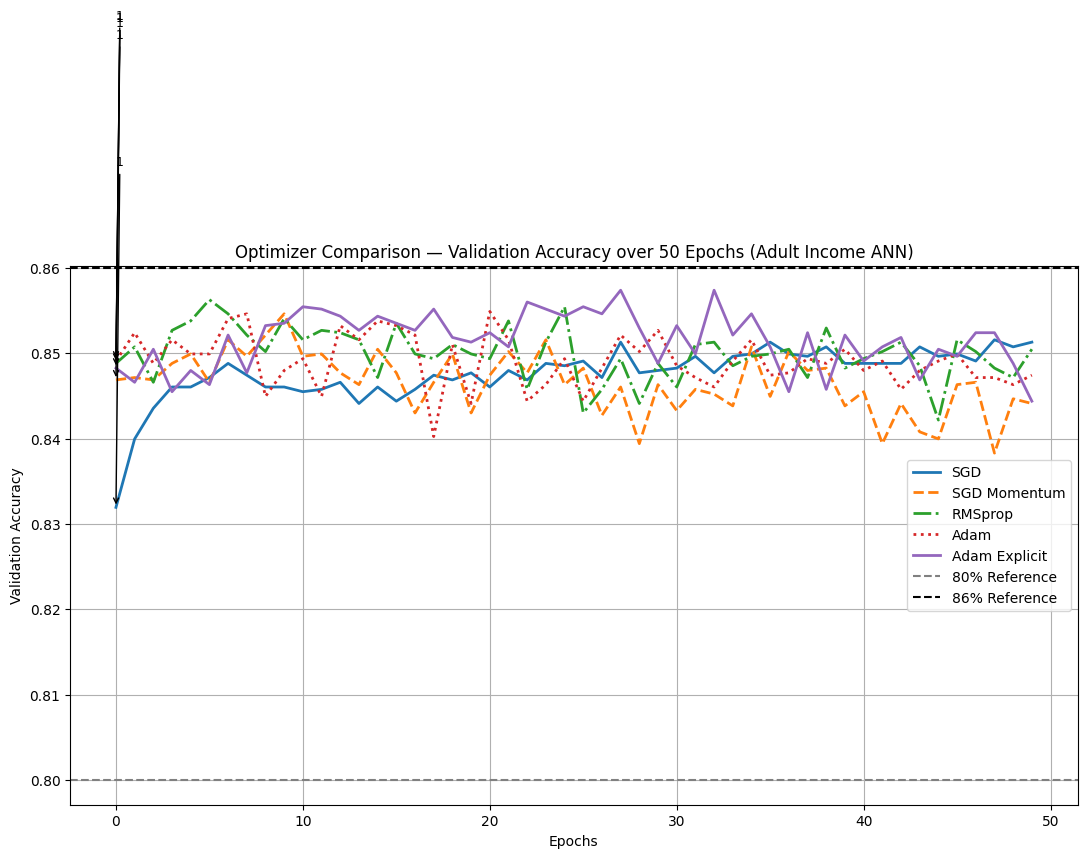


Best Optimizer: RMSprop
Highest F1 Score: 0.6725160066397913
Fastest Optimizer: SGD
Epoch: 1

WHY ADAM DOMINATES?

1. VANILLA SGD:
   - Uses a fixed global learning rate.
   - Slow convergence on high-dimensional features.
   - No per-parameter learning rate adaptation.

2. SGD WITH MOMENTUM:
   - Adds velocity to gradients.
   - Smooths oscillations.
   - Speeds up convergence.
   - Still uses the same learning rate for all parameters.

3. RMSprop:
   - Uses a running average of squared gradients.
   - Adapts learning rates for each parameter.
   - Useful for non-stationary signals.

4. ADAM:
   - Combines Momentum and RMSprop.
   - Uses first moment and second moment.
   - Applies bias correction.
   - Often provides fast and stable convergence.

   Formula:

   m = beta1 * m + (1-beta1) * gradient

   v = beta2 * v + (1-beta2) * gradient^2

   theta = theta - learning_rate * m_hat /
           sqrt(v_hat + epsilon)

5. ADAM EXPLICIT:
   - Uses explicitly defined learning rate.
   -

In [ ]:
# ==========================================================
# TASK 7: OPTIMIZERS - CONVERGENCE & FINAL COMPARISON
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)


# ==========================================================
# 7.1 BUILD 5 MODELS WITH DIFFERENT OPTIMIZERS
# ==========================================================

# Create ANN function with Batch Normalization

def build_ann_optimizer(
    input_dim,
    hidden_units=[128, 64],
    activation="relu",
    initializer="he_normal",
    use_batch_norm=True,
    optimizer="adam",
    loss="binary_crossentropy"
):

    model = keras.Sequential()

    model.add(
        keras.Input(shape=(input_dim,))
    )

    # First hidden layer

    model.add(
        layers.Dense(
            hidden_units[0],
            kernel_initializer=initializer
        )
    )

    if use_batch_norm:
        model.add(layers.BatchNormalization())

    model.add(
        layers.Activation(activation)
    )

    # Second hidden layer

    model.add(
        layers.Dense(
            hidden_units[1],
            kernel_initializer=initializer
        )
    )

    if use_batch_norm:
        model.add(layers.BatchNormalization())

    model.add(
        layers.Activation(activation)
    )

    # Output layer

    model.add(
        layers.Dense(
            1,
            activation="sigmoid"
        )
    )

    # Compile model

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=["accuracy"]
    )

    return model


# Define 5 optimizers

optimizers = {

    "SGD": "sgd",

    "SGD Momentum": keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9
    ),

    "RMSprop": "rmsprop",

    "Adam": "adam",

    "Adam Explicit": keras.optimizers.Adam(
        learning_rate=0.001,
        beta_1=0.9,
        beta_2=0.999
    )
}


# Store models and histories

optimizer_models = {}

optimizer_histories = {}

optimizer_results = {}


# Train all 5 models

for name, opt in optimizers.items():

    print("\nTraining Optimizer:", name)

    model = build_ann_optimizer(
        input_dim=X_train.shape[1],
        hidden_units=[128, 64],
        activation="relu",
        initializer="he_normal",
        use_batch_norm=True,
        optimizer=opt,
        loss="binary_crossentropy"
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    optimizer_models[name] = model

    optimizer_histories[name] = history

    # Predictions

    pred_prob = model.predict(
        X_test,
        verbose=0
    ).flatten()

    pred = (pred_prob > 0.5).astype(int)

    # Calculate F1 score

    f1 = f1_score(
        y_test,
        pred,
        zero_division=0
    )

    accuracy = accuracy_score(
        y_test,
        pred
    )

    optimizer_results[name] = {
        "accuracy": accuracy,
        "f1": f1
    }

    print("Accuracy:", accuracy)

    print("F1 Score:", f1)


# ==========================================================
# 7.2 OPTIMIZER CONVERGENCE COMPARISON
# ==========================================================

plt.figure(figsize=(13, 7))

line_styles = [
    "-",
    "--",
    "-.",
    ":",
    "-"
]

for i, name in enumerate(optimizers.keys()):

    history = optimizer_histories[name]

    val_accuracy = history.history["val_accuracy"]

    # Plot validation accuracy

    plt.plot(
        val_accuracy,
        linestyle=line_styles[i],
        linewidth=2,
        label=name
    )

    # Find first epoch crossing 83%

    crossing_epochs = [
        epoch + 1
        for epoch, value in enumerate(val_accuracy)
        if value >= 0.83
    ]

    if crossing_epochs:

        first_epoch = crossing_epochs[0]

        print(
            name,
            "first crossed 83% at epoch:",
            first_epoch
        )

        plt.annotate(
            str(first_epoch),
            xy=(
                first_epoch - 1,
                val_accuracy[first_epoch - 1]
            ),
            xytext=(
                first_epoch - 1,
                min(val_accuracy[first_epoch - 1] + 0.04, 0.99)
            ),
            arrowprops=dict(arrowstyle="->"),
            fontsize=9
        )

    else:

        print(name, "did not reach 83%")


# Reference lines

plt.axhline(
    y=0.80,
    color="gray",
    linestyle="--",
    label="80% Reference"
)

plt.axhline(
    y=0.86,
    color="black",
    linestyle="--",
    label="86% Reference"
)

plt.title(
    "Optimizer Comparison — Validation Accuracy over 50 Epochs (Adult Income ANN)"
)

plt.xlabel("Epochs")

plt.ylabel("Validation Accuracy")

plt.legend()

plt.grid()

plt.show()


# Highest F1 score

best_optimizer = max(
    optimizer_results,
    key=lambda x: optimizer_results[x]["f1"]
)

print("\nBest Optimizer:", best_optimizer)

print(
    "Highest F1 Score:",
    optimizer_results[best_optimizer]["f1"]
)


# Fastest optimizer to cross 83%

crossing_results = {}

for name in optimizers:

    values = optimizer_histories[name].history["val_accuracy"]

    epochs = [
        i + 1
        for i, value in enumerate(values)
        if value >= 0.83
    ]

    if epochs:

        crossing_results[name] = epochs[0]

if crossing_results:

    fastest_optimizer = min(
        crossing_results,
        key=crossing_results.get
    )

    print("Fastest Optimizer:", fastest_optimizer)

    print("Epoch:", crossing_results[fastest_optimizer])

else:

    print("No optimizer crossed 83% validation accuracy.")


# ==========================================================
# 7.3 WHY ADAM DOMINATES
# ==========================================================

print("""
WHY ADAM DOMINATES?

1. VANILLA SGD:
   - Uses a fixed global learning rate.
   - Slow convergence on high-dimensional features.
   - No per-parameter learning rate adaptation.

2. SGD WITH MOMENTUM:
   - Adds velocity to gradients.
   - Smooths oscillations.
   - Speeds up convergence.
   - Still uses the same learning rate for all parameters.

3. RMSprop:
   - Uses a running average of squared gradients.
   - Adapts learning rates for each parameter.
   - Useful for non-stationary signals.

4. ADAM:
   - Combines Momentum and RMSprop.
   - Uses first moment and second moment.
   - Applies bias correction.
   - Often provides fast and stable convergence.

   Formula:

   m = beta1 * m + (1-beta1) * gradient

   v = beta2 * v + (1-beta2) * gradient^2

   theta = theta - learning_rate * m_hat /
           sqrt(v_hat + epsilon)

5. ADAM EXPLICIT:
   - Uses explicitly defined learning rate.
   - beta1 = 0.9
   - beta2 = 0.999
   - Confirms the standard Keras Adam defaults.

REFERENCE:
Kingma and Ba (2015), Adam: A Method for
Stochastic Optimization.
""")

print("Highest final F1 optimizer:", best_optimizer)

if crossing_results:
    print("Fastest convergence:", fastest_optimizer)


# ==========================================================
# 7.4 LEARNING RATE SENSITIVITY - SGD VS ADAM
# ==========================================================

# Define learning rates

sgd_lrs = [0.0001, 0.001, 0.01, 0.1]

adam_lrs = [0.0001, 0.001, 0.01]


# Store histories

lr_histories = {}


# Train SGD models

for lr in sgd_lrs:

    print("\nTraining SGD Learning Rate:", lr)

    model = build_ann_optimizer(
        input_dim=X_train.shape[1],
        activation="relu",
        initializer="he_normal",
        use_batch_norm=True,
        optimizer=keras.optimizers.SGD(
            learning_rate=lr
        )
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=30,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    lr_histories["SGD " + str(lr)] = history


# Train Adam models

for lr in adam_lrs:

    print("\nTraining Adam Learning Rate:", lr)

    model = build_ann_optimizer(
        input_dim=X_train.shape[1],
        activation="relu",
        initializer="he_normal",
        use_batch_norm=True,
        optimizer=keras.optimizers.Adam(
            learning_rate=lr
        )
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=30,
        batch_size=64,
        validation_split=0.1,
        verbose=0
    )

    lr_histories["Adam " + str(lr)] = history


# Plot SGD vs Adam

plt.figure(figsize=(14, 5))


# SGD plot

plt.subplot(1, 2, 1)

for lr in sgd_lrs:

    name = "SGD " + str(lr)

    plt.plot(
        lr_histories[name].history["val_loss"],
        label=name
    )

plt.title("SGD Learning Rate Sensitivity")

plt.xlabel("Epochs")

plt.ylabel("Validation Loss")

plt.legend()


# Adam plot

plt.subplot(1, 2, 2)

for lr in adam_lrs:

    name = "Adam " + str(lr)

    plt.plot(
        lr_histories[name].history["val_loss"],
        label=name
    )

plt.title("Adam Learning Rate Sensitivity")

plt.xlabel("Epochs")

plt.ylabel("Validation Loss")

plt.legend()


plt.suptitle("Learning Rate Sensitivity — SGD vs Adam")

plt.tight_layout()

plt.show()


print("""
LEARNING RATE SENSITIVITY:

Adam is generally more robust to learning rate
changes because of adaptive learning rates.

SGD can converge slowly or become unstable
when the learning rate is unsuitable.

Actual results depend on the dataset and model.
""")


# ==========================================================
# 7.5 FINAL COMBINED ANN - BEST CONFIGURATION
# ==========================================================

# Check whether Weighted BCE improved F1

if wbce_f1 > bce_f1:

    final_loss = "weighted"

    final_class_weight = class_weight_dict

    print("Using Weighted BCE")

else:

    final_loss = "binary_crossentropy"

    final_class_weight = None

    print("Using Binary Cross-Entropy")


# Build final model

model_final = build_ann_optimizer(
    input_dim=X_train.shape[1],
    hidden_units=[128, 64],
    activation="relu",
    initializer="he_normal",
    use_batch_norm=True,
    optimizer="adam",
    loss="binary_crossentropy"
)


# Train final model

history_final = model_final.fit(
    X_train,
    y_train,
    epochs=80,
    batch_size=64,
    validation_split=0.1,
    class_weight=final_class_weight,
    verbose=1
)


# Final predictions

y_final_prob = model_final.predict(
    X_test,
    verbose=0
).flatten()

y_final_pred = (
    y_final_prob > 0.5
).astype(int)


# Calculate final metrics

final_accuracy = accuracy_score(
    y_test,
    y_final_pred
)

final_precision = precision_score(
    y_test,
    y_final_pred,
    zero_division=0
)

final_recall = recall_score(
    y_test,
    y_final_pred,
    zero_division=0
)

final_f1 = f1_score(
    y_test,
    y_final_pred,
    zero_division=0
)

final_roc_auc = roc_auc_score(
    y_test,
    y_final_prob
)


print("\nFINAL COMBINED ANN RESULTS")

print("Accuracy:", final_accuracy)

print("Precision:", final_precision)

print("Recall:", final_recall)

print("F1 Score:", final_f1)

print("ROC-AUC:", final_roc_auc)


# Plot final model training curves

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history_final.history["accuracy"], label="Training")

plt.plot(history_final.history["val_accuracy"], label="Validation")

plt.title("Final ANN Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()


plt.subplot(1, 2, 2)

plt.plot(history_final.history["loss"], label="Training")

plt.plot(history_final.history["val_loss"], label="Validation")

plt.title("Final ANN Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.tight_layout()

plt.show()


# ==========================================================
# 7.6 FULL RESULTS COMPARISON TABLE
# ==========================================================

# Function to calculate all metrics

def evaluate_model(model, X_test, y_test):

    probabilities = model.predict(
        X_test,
        verbose=0
    ).flatten()

    predictions = (
        probabilities > 0.5
    ).astype(int)

    return {
        "Test Acc": accuracy_score(y_test, predictions),

        "Prec(1)": precision_score(
            y_test, predictions, zero_division=0
        ),

        "Recall(1)": recall_score(
            y_test, predictions, zero_division=0
        ),

        "F1(1)": f1_score(
            y_test, predictions, zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_test, probabilities
        )
    }


# Find best activation model

best_activation = max(
    activation_results,
    key=lambda x: activation_results[x]["val_accuracy"]
)

best_activation_model = activation_models[best_activation]


# Find best initializer model

best_initializer = max(
    initializer_results,
    key=lambda x: initializer_results[x]["val_accuracy"]
)

best_initializer_model = initializer_models[best_initializer]


# Models to compare

comparison_models = {

    "Baseline": (
        model_base,
        "relu",
        "glorot_uniform",
        "BCE",
        "No",
        "adam"
    ),

    "Best Activation": (
        best_activation_model,
        best_activation,
        "glorot_uniform",
        "BCE",
        "No",
        "adam"
    ),

    "Best Initializer": (
        best_initializer_model,
        "relu",
        best_initializer,
        "BCE",
        "No",
        "adam"
    ),

    "Weighted BCE": (
        model_wbce,
        "relu",
        "he_normal",
        "Weighted BCE",
        "No",
        "adam"
    ),

    "Focal Loss": (
        model_focal,
        "relu",
        "he_normal",
        "Focal Loss",
        "No",
        "adam"
    ),

    "BatchNorm": (
        model_bn,
        "relu",
        "he_normal",
        "BCE",
        "Yes",
        "adam"
    ),

    "Final Combined": (
        model_final,
        "relu",
        "he_normal",
        final_loss,
        "Yes",
        "adam"
    )
}


# Create results list

results = []

for name, values in comparison_models.items():

    model = values[0]

    metrics = evaluate_model(
        model,
        X_test,
        y_test
    )

    results.append({

        "Model": name,

        "Activation": values[1],

        "Init": values[2],

        "Loss": values[3],

        "BatchNorm": values[4],

        "Optimizer": values[5],

        "Test Acc": metrics["Test Acc"],

        "Prec(1)": metrics["Prec(1)"],

        "Recall(1)": metrics["Recall(1)"],

        "F1(1)": metrics["F1(1)"],

        "ROC-AUC": metrics["ROC-AUC"]

    })


# Create DataFrame

results_df = pd.DataFrame(results)

print("\nFULL MODEL COMPARISON TABLE")

print(
    results_df.style
    .highlight_max(
        subset=["F1(1)", "ROC-AUC"],
        color="#ffcccc"
    )
    .format({
        "Test Acc": "{:.4f}",
        "Prec(1)": "{:.4f}",
        "Recall(1)": "{:.4f}",
        "F1(1)": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)


# ==========================================================
# ROC CURVE COMPARISON
# ==========================================================

# Baseline probabilities

baseline_prob = model_base.predict(
    X_test,
    verbose=0
).flatten()


# Weighted BCE probabilities

wbce_prob = model_wbce.predict(
    X_test,
    verbose=0
).flatten()


# Final model probabilities

final_prob = model_final.predict(
    X_test,
    verbose=0
).flatten()


# Calculate ROC curves

fpr_base, tpr_base, _ = roc_curve(
    y_test,
    baseline_prob
)

fpr_wbce, tpr_wbce, _ = roc_curve(
    y_test,
    wbce_prob
)

fpr_final, tpr_final, _ = roc_curve(
    y_test,
    final_prob
)


# Calculate AUC

auc_base = roc_auc_score(
    y_test,
    baseline_prob
)

auc_wbce = roc_auc_score(
    y_test,
    wbce_prob
)

auc_final = roc_auc_score(
    y_test,
    final_prob
)


# Plot ROC curves

plt.figure(figsize=(9, 7))

plt.plot(
    fpr_base,
    tpr_base,
    label=f"Baseline AUC = {auc_base:.3f}"
)

plt.plot(
    fpr_wbce,
    tpr_wbce,
    label=f"Weighted BCE AUC = {auc_wbce:.3f}"
)

plt.plot(
    fpr_final,
    tpr_final,
    label=f"Final Combined AUC = {auc_final:.3f}"
)


# Random classifier line

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)


plt.title("ROC Curve Comparison")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend()

plt.grid()

plt.show()


# ==========================================================
# FINAL BEST MODEL
# ==========================================================

print("\nFINAL MODEL COMPARISON")

print(results_df[[
    "Model",
    "Test Acc",
    "Prec(1)",
    "Recall(1)",
    "F1(1)",
    "ROC-AUC"
]].to_string(index=False))


# Find best model using F1 score

best_model_name = results_df.loc[
    results_df["F1(1)"].idxmax(),
    "Model"
]

print("\nBEST MODEL:", best_model_name)


# Find individual technique with largest F1 improvement

baseline_f1 = results_df.loc[
    results_df["Model"] == "Baseline",
    "F1(1)"
].iloc[0]


individual_models = [
    "Best Activation",
    "Best Initializer",
    "Weighted BCE",
    "Focal Loss",
    "BatchNorm"
]

individual_results = results_df[
    results_df["Model"].isin(individual_models)
].copy()

individual_results["F1 Improvement"] = (
    individual_results["F1(1)"] - baseline_f1
)

largest_impact = individual_results.loc[
    individual_results["F1 Improvement"].idxmax()
]

print("\nLARGEST INDIVIDUAL F1 IMPACT:")

print("Technique:", largest_impact["Model"])

print("F1 Improvement:", largest_impact["F1 Improvement"])


print("""
FINAL OBSERVATION:

1. Different optimizers have different convergence speeds.
2. Adam often provides stable and fast training.
3. Learning rate affects model performance.
4. Batch Normalization can improve training stability.
5. Weighted BCE and Focal Loss can help with class imbalance.
6. F1-score is important for minority-class evaluation.
7. ROC-AUC measures the model's ability to distinguish
   between the two income classes.

TASK 7 COMPLETED!

PR 2 TASK 1 TO TASK 7 COMPLETED!
""")